In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["font.family"] = "Arial"

from additives_microbiota.plotting import process_string, process_string_pretty_vars, ecode_category_colors

### Loading Additive intake data

In [2]:
additive_intake = pd.read_csv(
    "../../data/additive_analysis_files/avg_daily_additive_intake_across_users.csv",
    index_col=0,
)

additive_vars = list(additive_intake.columns)
additive_vars = [i for i in additive_vars if i != "total_additive_intake"]
print("total additive vars: ", len(additive_vars))

total additive vars:  257


## Using NMF from sklearn


In [3]:
from sklearn.decomposition import NMF
from scipy.cluster.hierarchy import linkage, cophenet
from scipy.spatial.distance import squareform


def perform_nmf(
    X, n_components, random_state=None, init="nndsvd", max_iter=5000, tol=1e-4
):
    model = NMF(
        n_components=n_components,
        init=init,
        solver="cd",
        beta_loss="frobenius",
        max_iter=max_iter,
        tol=tol,
        random_state=random_state,
    )
    W = model.fit_transform(X)
    H = model.components_
    return W, H


def cophenetic_coeff_for_k(X, k, n_runs=20):
    n = X.shape[0]
    consensus = np.zeros((n, n))
    for i in range(n_runs):
        W, _ = perform_nmf(X, k, init="random", random_state=i)
        labels = W.argmax(axis=1)
        C = (labels[:, None] == labels[None, :]).astype(float)
        consensus += C
    consensus /= n_runs

    D = 1 - consensus
    d_cond = squareform(D, checks=False)
    if np.allclose(d_cond, 0):
        return np.nan

    Z = linkage(d_cond, method="average")
    coph, _ = cophenet(Z, d_cond)
    return coph


def find_optimal_k(X, k_min=2, k_max=8, n_runs=20):
    return {
        k: cophenetic_coeff_for_k(X, k, n_runs=n_runs) for k in range(k_min, k_max + 1)
    }


def create_additive_mixtures(X, additive_vars, n_components, threshold=0.05):
    """
    Identify NMF-based additive mixtures.
    """
    W, H = perform_nmf(X, n_components, random_state=0)
    loadings_df = pd.DataFrame(
        H, columns=additive_vars, index=[f"Mixture{i+1}" for i in range(n_components)]
    )
    scores_df = pd.DataFrame(W, columns=loadings_df.index)
    emblematic = {
        mix: loadings_df.loc[mix][loadings_df.loc[mix] >= threshold]
        for mix in loadings_df.index
    }

    loadings_norm = loadings_df.div(loadings_df.sum(axis=1), axis=0)
    emblematic_rel = {
        mix: row[row >= threshold].sort_values(ascending=False)
        for mix, row in loadings_norm.iterrows()
    }

    return loadings_df, scores_df, emblematic, emblematic_rel


# Running:
X = additive_intake[additive_vars].values

cophens = find_optimal_k(X, k_min=2, k_max=10, n_runs=30)
cophens

{2: np.float64(0.9762696472754222),
 3: np.float64(0.9640048136504547),
 4: np.float64(0.8994815079593128),
 5: np.float64(0.8561748860802209),
 6: np.float64(0.8076674486286247),
 7: np.float64(0.8255924962368174),
 8: np.float64(0.8046699823270459),
 9: np.float64(0.7903346317217802),
 10: np.float64(0.7841528996861812)}

#### Running at Optimal K

In [4]:
optimal_k = 3

mixtures = ["Mixture" + str(i) for i in range(1, optimal_k + 1)]

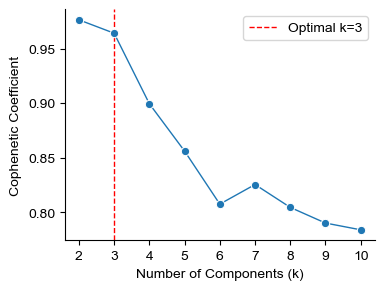

In [5]:
fig, ax = plt.subplots(figsize=(4, 3))
sns.lineplot(
    x=list(cophens.keys()), y=list(cophens.values()), marker="o", ax=ax, linewidth=1
)
ax.axvline(
    x=optimal_k,
    color="red",
    linestyle="--",
    label=f"Optimal k={optimal_k}",
    linewidth=1,
    zorder=1,
)
ax.set_xlabel("Number of Components (k)")
ax.set_ylabel("Cophenetic Coefficient")
ax.set_xticks(list(cophens.keys()))
ax.legend()
sns.despine()
plt.savefig(
    "../figures/mixtures/mixtures_cophenetic_coefficient.png",
    dpi=300,
    bbox_inches="tight",
)

In [6]:
loadings, scores, emblematic, emblematic_rel = create_additive_mixtures(
    X, additive_vars, n_components=optimal_k, threshold=0.05
)

for mix in scores.columns:  # the columns are mixture names
    additive_intake[mix] = scores[mix].values

In [7]:
for mix, cats in emblematic.items():
    print(f"{mix}:")
    print(cats, "\n")

Mixture1:
e414      0.137624
e200      0.069023
e290      0.082455
e100      0.142593
e407      0.380760
            ...   
e504      0.065381
e202      0.685748
e500ii    0.768034
e422      0.161778
e503      0.606813
Name: Mixture1, Length: 85, dtype: float64 

Mixture2:
e290       1.955617
e407       0.101148
e952       0.163342
e101       0.117440
e331iii    0.200534
e150       0.074279
e950       2.095098
e270       0.053647
e330       0.556569
e412       0.051041
e150d      1.637798
e331       0.596553
e150a      0.130978
e338       0.442607
e955       0.188039
e428       0.055872
e300       0.069921
e951       1.823176
Name: Mixture2, dtype: float64 

Mixture3:
e472a     0.273814
e414      1.209639
e553      0.573997
e965      1.186491
e306      0.269763
e321      0.340010
e953      1.125617
e903      1.125805
e150      0.137446
e171      0.964633
e950      1.230103
e967      0.803469
e296      0.055855
e322      0.407936
e420      1.248633
e307      0.339369
e170      0.271845


In [8]:
for mix, cats in emblematic_rel.items():
    print(f"{mix}:")
    print(cats, "\n")

Mixture1:
e322     0.107329
e330     0.097828
e322i    0.077808
e500     0.070908
Name: Mixture1, dtype: float64 

Mixture2:
e950     0.184413
e290     0.172135
e951     0.160478
e150d    0.144161
e331     0.052509
Name: Mixture2, dtype: float64 

Mixture3:
e420      0.072638
e950      0.071561
e414      0.070370
e965      0.069023
e903      0.065493
e953      0.065482
e422      0.064669
e951      0.061207
e171      0.056117
e965ii    0.051542
Name: Mixture3, dtype: float64 



In [9]:
for k, v in emblematic.items():
    print(k, len(v))

for k, v in emblematic_rel.items():
    print("Relative", k, len(v))

Mixture1 85
Mixture2 18
Mixture3 27
Relative Mixture1 4
Relative Mixture2 5
Relative Mixture3 10


## Save mixtures to csv

In [10]:
total_additive_intake_and_mixtures = additive_intake[
    [i for i in additive_intake if "Mixture" in i] + ["total_additive_intake"]
]

total_additive_intake_and_mixtures.to_csv(
    "../../data/metadata_files/total_additive_intake_and_mixtures.csv"
)

### Combining with metadata, additive intake by category, and Mixtures


In [11]:
meta = pd.read_csv("../../data/metadata_files/fay_meta_paper_version.csv", index_col=0)
print(meta.shape)

(976, 191)


In [12]:
# Loading additive intake across users by additive category
additive_intake_by_category = pd.read_csv(
    "../../data/additive_analysis_files/avg_daily_additive_intake_across_users_by_category.csv",
    index_col=0,
)

meta = pd.merge(meta, additive_intake_by_category, on="subject_key")
print(meta.shape)

meta.set_index("subject_app_key", inplace=True)

meta = meta.merge(total_additive_intake_and_mixtures, on="subject_key")

print(meta.shape)

(975, 198)
(975, 201)


### Saving metadata with mixtures

In [13]:
meta.to_csv("../../data/metadata_files/meta_mixtures.csv")

# Plotting: 
1. Clustermap of Mixture - Additive Loadings
2. Mixture Stability

### 1. Clustermap of Mixture - Additive Loadings

In [14]:
emblematic_type = "all"

if emblematic_type == "relative":
    emblematic_dict = emblematic_rel
else:
    emblematic_dict = emblematic

mixture_cols = [col for col in emblematic_dict.keys()]
unique_additives = set().union(*[emblematic_dict[m].index for m in mixture_cols])
loadings[list(unique_additives)].T.sort_values(mixture_cols)

,Mixture1,Mixture2,Mixture3
e472a,0.000000,0.000000,0.273814
e307,0.000000,0.000000,0.339369
e553b,0.000000,0.000000,0.573997
e553,0.000000,0.000000,0.573997
e967,0.000000,0.000000,0.803469
...,...,...,...
e500ii,0.768034,0.000000,0.000000
e500,1.804778,0.020832,0.000000
e322i,1.980397,0.000000,0.258910
e330,2.489975,0.556569,0.000000


In [15]:
additive_names = pd.read_csv("../../data/additive_name_mapping_v3_merged.csv")

clustermap_data = loadings[list(unique_additives)].T

clustermap_data["type"] = [
    additive_names[additive_names["ecode"] == a]["category"].values[0]
    for a in clustermap_data.index
]

## Add color based on Additive Category
clustermap_data["color"] = clustermap_data["type"].map(ecode_category_colors)

clustermap_data.index = [
    (
        f"{a} - {additive_names[additive_names['ecode'] == a]['name'].values[0]}"
        if a in additive_names["ecode"].values
        else a
    )
    for a in clustermap_data.index
]

## Save loadings to csv
clustermap_data.to_csv("../outputs/supplementary_files/mixtures_loadings.csv")

clustermap_data

,Mixture1,Mixture2,Mixture3,type,color
e631 - Disodium inosinate,0.079149,0.003580,0.000000,flavor_enhancers,#ffb3e6
e500ii - Sodium hydrogen carbonate,0.768034,0.000000,0.000000,ph_regulators_anti_caking_leavening_agents,#b3de69
e472b - Lactic acid esters of mono- and diglycerides of fatty acids,0.054142,0.000000,0.000000,thickeners_stabilizers_emulsifiers_gelling_agents,#ffcc99
e224 - Potassium metabisulphite,0.058672,0.000000,0.007714,preservatives_antioxidants,#66b3ff
e260 - Acetic acid,0.119311,0.008705,0.011018,ph_regulators_anti_caking_leavening_agents,#b3de69
...,...,...,...,...,...
e440 - Pectins,0.519442,0.039696,0.009111,thickeners_stabilizers_emulsifiers_gelling_agents,#ffcc99
e200 - Sorbic acid,0.069023,0.010423,0.007672,preservatives_antioxidants,#66b3ff
e160ai - Carotenes,0.058910,0.006707,0.000000,colorants,gold
e322i - Lecithins,1.980397,0.000000,0.258910,thickeners_stabilizers_emulsifiers_gelling_agents,#ffcc99


In [16]:
# Create sets of additives that have a loading > 0.25 for each mixture
mix_sets = []
for i in range(1, optimal_k + 1):
    # For each mixture, find additives with loading > 0.25
    mix_set = set(clustermap_data[clustermap_data[f"Mixture{i}"] > 0.3].index)
    mix_sets.append(mix_set)

# Combine all sets to get additives that are relevant in at least one mixture
relevant_additives_for_clusterplot = list(set.union(*mix_sets))

# Filter the data to only include relevant additives for the cluster plot
clustermap_data = clustermap_data[
    clustermap_data.index.isin(relevant_additives_for_clusterplot)
]

In [17]:
clustermap_data

,Mixture1,Mixture2,Mixture3,type,color
e500ii - Sodium hydrogen carbonate,0.768034,0.000000,0.000000,ph_regulators_anti_caking_leavening_agents,#b3de69
e955 - Sucralose,0.259173,0.188039,0.515608,sweeteners_glazing_agents,#c2c2f0
e953 - lsomalt,0.015586,0.000000,1.125617,sweeteners_glazing_agents,#c2c2f0
e150d - Sulphite ammonia caramel,0.000000,1.637798,0.000000,colorants,gold
e300 - Ascorbic acid,0.682767,0.069921,0.000000,preservatives_antioxidants,#66b3ff
e950 - Acesulfame K,0.019367,2.095098,1.230103,sweeteners_glazing_agents,#c2c2f0
e500 - Sodium carbonates,1.804778,0.020832,0.000000,ph_regulators_anti_caking_leavening_agents,#b3de69
e171 - Titanium dioxide,0.000000,0.000000,0.964633,colorants,gold
e553b - Talc,0.000000,0.000000,0.573997,ph_regulators_anti_caking_leavening_agents,#b3de69
e202 - Potassium sorbate,0.685748,0.015583,0.000000,preservatives_antioxidants,#66b3ff


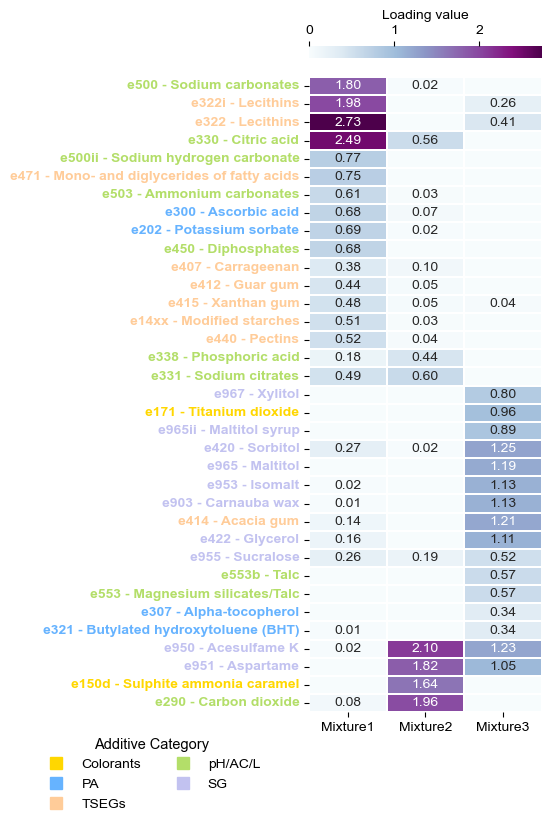

In [18]:
clustermap_plot_data = clustermap_data.drop(columns=["type", "color"], axis=1)

# prepare annotation labels, showing "0" for exact zeros
labels = clustermap_plot_data.map(lambda x: "" if x < 0.01 else f"{x:.2f}")

# First get the clustering order
g = sns.clustermap(
    clustermap_plot_data,
    cmap="BuPu",
    figsize=(3, 6),
    linewidth=0.1,
    col_cluster=False,
    row_cluster=True,
)
plt.close()

# Get the row order from the clustering
row_order = g.dendrogram_row.reordered_ind

# Create a new heatmap with the same ordering but without dendrograms
plt.figure(figsize=(3, 6 if emblematic_type == "relative" else 10))
ax = sns.heatmap(
    clustermap_plot_data.iloc[row_order],
    annot=labels.iloc[row_order],
    fmt="",
    cmap="BuPu",
    linewidth=0.1,
    yticklabels=1,
    cbar_kws={
        "label": (
            "Loading value" if emblematic_type == "all" else "Relative Loading value"
        ),
        "orientation": "horizontal",
        "location": "top",
        "pad": 0.025,
    },
)

# apply colors to ytick labels
row_colors = clustermap_data.iloc[row_order]["color"]
for tick_label, color in zip(ax.get_yticklabels(), row_colors):
    tick_label.set_color(color)
    tick_label.set_fontweight("bold")


# plt.xticks(rotation=0, rotation_mode="anchor", ha="right")

legend_handles = [
    plt.Line2D(
        [0],
        [0],
        marker="s",
        linestyle="",
        markersize=8,
        markerfacecolor=color,
        markeredgecolor=color,
        label=process_string_pretty_vars(label),
    )
    for label, color in ecode_category_colors.items()
    if label in clustermap_data["type"].unique()
]

ax.legend(
    handles=legend_handles,
    title="Additive Category",
    title_fontsize=10.5,
    loc="upper left",
    # bbox_to_anchor=(-1.2, 1.17),
    bbox_to_anchor=(-1.2, -0.02),
    frameon=False,
    ncol=2,
)

plt.savefig(
    f"../figures/mixtures/mixtures_loadings_{emblematic_type}_clustermap.png",
    dpi=300,
    bbox_inches="tight",
)

### 2. Mixture Stability Analysis

Mixture Stability Metrics (higher is better):
overall: 1.0000
Mixture1: 1.0000
Mixture2: 1.0000
Mixture3: 1.0000


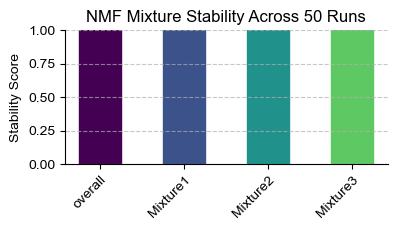

In [19]:
from sklearn.metrics import silhouette_score


def measure_mixture_stability(combined_loadings):
    """
    Calculate stability metrics for NMF mixtures using silhouette scores.

    Parameters:
    -----------
    combined_loadings : pandas DataFrame
        DataFrame containing loadings from multiple NMF runs with index in format 'Run{i}_Mixture{j}'

    Returns:
    --------
    dict
        Dictionary containing silhouette scores for each mixture and overall solution
    """
    # Extract mixture labels from index
    labels = []
    features = []

    for i, row in combined_loadings.iterrows():
        # Parse the index to get mixture number
        parts = i.split("_")
        mixture = int(parts[1].replace("Mixture", ""))

        # Add to lists
        labels.append(mixture)
        features.append(row.values)

    # Convert to arrays
    labels = np.array(labels)
    features = np.array(features)

    results = {}

    # Calculate overall silhouette score if we have multiple mixtures
    if len(np.unique(labels)) > 1:
        overall_silhouette = silhouette_score(features, labels, metric="cosine")
        results["overall"] = overall_silhouette

    # Calculate silhouette score for each mixture
    for mixture_num in np.unique(labels):
        # Get indices for this mixture
        mixture_indices = np.where(labels == mixture_num)[0]

        if len(mixture_indices) >= 2:  # Need at least 2 samples for silhouette
            # For each mixture, create an intra-mixture comparison
            # We use zero labels since we're measuring consistency within a single mixture
            mixture_features = features[mixture_indices]
            mixture_labels = np.zeros(len(mixture_indices))

            # Calculate average distance to centroid (a variation of silhouette)
            centroid = np.mean(mixture_features, axis=0)
            distances = np.array(
                [np.linalg.norm(f - centroid) for f in mixture_features]
            )
            avg_distance = np.mean(distances)
            normalized_distance = avg_distance / np.sqrt(
                mixture_features.shape[1]
            )  # Normalize by feature dimension

            # Lower distance = higher stability (invert for intuitive interpretation)
            stability_score = 1 / (1 + normalized_distance)

            results[f"Mixture{mixture_num}"] = stability_score

    return results


n_runs = 50
all_loadings = []

for i in range(n_runs):
    W, H = perform_nmf(X, len(mixtures), random_state=i)
    loadings_df = pd.DataFrame(
        H,
        columns=additive_vars,
        index=[f"Run{i+1}_Mixture{j+1}" for j in range(len(mixtures))],
    )
    all_loadings.append(loadings_df)

# Combine all loadings
combined_loadings = pd.concat(all_loadings)

stability_metrics = measure_mixture_stability(combined_loadings)

print("Mixture Stability Metrics (higher is better):")
for mix, score in stability_metrics.items():
    print(f"{mix}: {score:.4f}")

# Create bar plot
plt.figure(figsize=(4, 2.4))
bars = plt.bar(stability_metrics.keys(), stability_metrics.values(), width=0.5)

for i, bar in enumerate(bars):
    bar.set_color(plt.cm.viridis(i / len(stability_metrics)))

plt.ylabel("Stability Score")
plt.title(f"NMF Mixture Stability Across {n_runs} Runs")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.xticks(rotation=45, rotation_mode="anchor", ha="right")
sns.despine()
plt.tight_layout()

plt.savefig("../figures/mixtures/mixture_stability.png", dpi=300, bbox_inches="tight")